# Preference Tuning: Reward Models, RLHF and DPO

---

> **Post-training series (1 of 3).** **08 Preference Tuning** → [09 Reasoning at Inference Time](./09_inference_time_scaling_and_evaluation.ipynb) → `10` RLVR and GRPO. The three notebooks share one running analogy, a restaurant kitchen; each one opens a different station.

Creator: Chung-En Johnny Yu

Content updated: 2026-11-05

Hands-on practice this notebook on your Google Colab:
1. [Click here to open this notebook](https://colab.research.google.com/github/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/08_preference_tuning_rlhf_dpo.ipynb)
2. Now, run the code and practice it!

Extends `06_finetuning_instructions.ipynb` and `07_lora_peft.ipynb`. Instruction fine-tuning teaches a model to *answer*; preference tuning teaches it *which of two acceptable answers people prefer*. This notebook builds the three ideas behind that step from the ground up: a reward model learned from votes, RLHF's "maximize reward but stay close to where you started", and DPO, which reaches the same goal without a reward model or reinforcement learning.

**Sources** — sections taken from Raschka are tagged; everything else is written for this notebook:

| Tag | Source |
|---|---|
| 📗 **[DPO bonus]** | Sebastian Raschka, LLMs-from-scratch [`ch07/04_preference-tuning-with-dpo/dpo-from-scratch.ipynb`](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch07/04_preference-tuning-with-dpo/dpo-from-scratch.ipynb) — DPO loss and log-probability code, two dataset entries, and the training log and sample outputs of his saved run (copied into `08-preference_tuning_rlhf_dpo/data/`) |

Other references, cited where used: InstructGPT (Ouyang et al., 2022), PPO (Schulman et al., 2017), DPO (Rafailov et al., 2023), reward-model over-optimization (Gao et al., 2022), and Nathan Lambert's *The RLHF Book*.

> **How this notebook works.** We do not fine-tune a real model here: that needs a large GPU and is not the point. Instead, a toy "kitchen" with a tiny language model shows each mechanism in seconds on CPU, and the real-model result comes from Raschka's saved DPO run on GPT-2 medium, whose training log and outputs we load and plot. Every cell still runs, on a laptop or Colab CPU, in under a minute.

| Part | Content |
|---|---|
| 1 | The post-training stack, and what SFT cannot teach |
| 2 | Preference data, and a toy kitchen where the true preference is known |
| 3 | Reward models: the Bradley–Terry loss |
| 4 | RLHF: maximize reward, stay close to the reference (KL), PPO's clipping |
| 5 | DPO: the same goal without a reward model |
| 6 | Tests, β, and what happens when DPO trains too long |
| 7 | Reward hacking: when the critic loves garnish |
| 8 | The real run: Raschka's DPO on GPT-2 medium |
| 9 | Interview-style check questions |

---

In [1]:
import copy, itertools, json, math, os, sys, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib import patches

import plotly.graph_objects as go
import plotly.io as pio
if "google.colab" not in sys.modules:          # Colab picks its own renderer
    pio.renderers.default = "plotly_mimetype+notebook_connected"

INK, ACCENT, SOFT, BLUE, GREEN, GOLD = "#2b2d42", "#ef8354", "#bfc0c0", "#4f5d75", "#7fb069", "#d7b377"
torch.manual_seed(0)
print("torch", torch.__version__)

torch 2.13.0


## The running analogy: a restaurant kitchen

The whole post-training series uses one picture: **a restaurant kitchen training an apprentice chef**. Each notebook opens a different station; the rows for this notebook are in bold.

| In the kitchen | In post-training | Notebook |
|---|---|---|
| reading every cookbook in the library | pretraining | `04`, `06_pretraining_pipeline` |
| copying the head chef's dishes exactly | supervised fine-tuning (SFT) | `06_finetuning_instructions` |
| **a food critic who learned the customers' taste from "dish A or dish B?" vote cards** | **reward model (Bradley–Terry)** | **08** |
| **cooking, being scored by the critic, while a coach stops you drifting too far from your training** | **RLHF: maximize reward with a KL penalty (PPO)** | **08** |
| **learning straight from the vote cards, without hiring a critic** | **DPO** | **08** |
| **the critic loves garnish, so you pile on parsley** | **reward hacking / over-optimization** | **08** |
| cooking several versions and serving the one that passes the taste test | best-of-N with a verifier | 09 |
| a thermometer and a recipe checklist instead of a critic's opinion | verifiable reward | 09, 10 |
| cooking eight versions of the same dish and comparing each with the batch average | GRPO's group-relative advantage | 10 |

**Where the analogy breaks.** A critic scores the finished dish, but a language model is trained one token at a time, so a single score has to be spread over many small decisions. And the coach (the KL penalty) is a soft cost, not a rule: with a strong enough reward, the apprentice will still drift.

## 1. The post-training stack

After pretraining (`04_pretraining.ipynb`) a model can continue text; after instruction fine-tuning (`06_finetuning_instructions.ipynb`) it answers instructions by imitating demonstrations. But many prompts have **several acceptable answers** that differ in tone, length, safety or helpfulness. SFT has no way to say "this answer is better than that one": every demonstration is simply copied. Preference tuning adds exactly that signal.

| Stage | Data | Objective | Models in memory while training |
|---|---|---|---|
| Pretraining | raw text, trillions of tokens | next-token cross-entropy | 1 |
| SFT | (prompt, response) demonstrations | cross-entropy on the response | 1 |
| Reward model | (prompt, chosen, rejected) votes | Bradley–Terry (Part 3) | 1 |
| RLHF with PPO | prompts; responses sampled **online** from the policy | reward − β·KL (Part 4) | 4: policy, reference, reward, value |
| DPO | the same votes, **offline** | DPO loss (Part 5) | 2: policy, reference |

For scale: InstructGPT, whose recipe ChatGPT followed, used about 13k prompts for SFT, 33k for the reward model and 31k for PPO (Ouyang et al., 2022).

**In the kitchen.** The apprentice has read every cookbook and copied the head chef. Now the restaurant wants dishes *customers prefer*, and the only signal is a stack of vote cards.

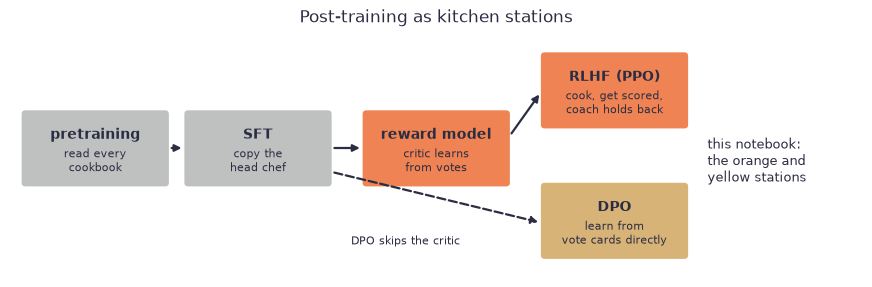

In [2]:
# The post-training pipeline as kitchen stations
stations = [("pretraining", "read every\ncookbook", SOFT), ("SFT", "copy the\nhead chef", SOFT),
            ("reward model", "critic learns\nfrom votes", ACCENT), ("RLHF (PPO)", "cook, get scored,\ncoach holds back", ACCENT),
            ("DPO", "learn from\nvote cards directly", GOLD)]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.set_xlim(0, 11); ax.set_ylim(0, 3.4); ax.axis("off")
xs = [0.2, 2.3, 4.6, 6.9, 6.9]
ys = [1.3, 1.3, 1.3, 2.1, 0.3]
for (title, sub, color), x, y in zip(stations, xs, ys):
    ax.add_patch(patches.FancyBboxPatch((x, y), 1.8, 0.95, boxstyle="round,pad=0.05", fc=color, ec="none"))
    ax.text(x + 0.9, y + 0.66, title, ha="center", va="center", fontsize=10, weight="bold", color=INK)
    ax.text(x + 0.9, y + 0.3, sub, ha="center", va="center", fontsize=8, color=INK)
arrow = dict(arrowstyle="-|>", lw=1.6, color=INK)
ax.annotate("", xy=(2.25, 1.78), xytext=(2.05, 1.78), arrowprops=arrow)
ax.annotate("", xy=(4.55, 1.78), xytext=(4.15, 1.78), arrowprops=arrow)
ax.annotate("", xy=(6.85, 2.55), xytext=(6.45, 1.95), arrowprops=arrow)
ax.annotate("", xy=(6.85, 0.75), xytext=(4.15, 1.45), arrowprops=dict(arrowstyle="-|>", lw=1.6, color=INK, ls="--"))
ax.text(4.4, 0.45, "DPO skips the critic", fontsize=8, color=INK)
ax.text(9.0, 1.6, "this notebook:\nthe orange and\nyellow stations", fontsize=9, color=INK, va="center")
ax.set_title("Post-training as kitchen stations", color=INK)
plt.show()

## 2. Preference data

📗 *[DPO bonus] dataset entries*

A preference dataset stores, for each prompt, a **chosen** and a **rejected** response. Raschka's DPO notebook uses 1,100 instructions where the two responses differ mostly in politeness (he generated them with Llama 3.1 through Ollama). Two entries:

| Instruction | Chosen | Rejected |
|---|---|---|
| Identify the correct spelling of the following word. *Input:* Ocassion | The correct spelling is 'Occasion.' | The correct spelling is obviously 'Occasion.' |
| What is an antonym of 'complicated'? | A suitable antonym for 'complicated' would be 'simple'. | An antonym of 'complicated' is 'simple'. |

Both responses are *correct*; the vote is about style. That is exactly the kind of signal SFT cannot express.

### A toy kitchen where the true preference is known

With real data we never know the "true" quality of an answer, so we cannot check whether training made answers better or only made a score go up. In a toy kitchen we can. Customers order **soup, salad or pasta**, and the apprentice answers with one of six responses. A hidden rule defines true quality:

| Rule | Points |
|---|---|
| names the dish that was ordered | +1 (wrong dish: −2) |
| polite (", enjoy") | +1 |
| each "parsley" | −0.5 |
| a one-word answer | −0.5 |

In [3]:
DISHES = ["soup", "salad", "pasta"]
TEMPLATES = {
    "plain":   "here is your {d}",
    "polite":  "here is your {d} , enjoy",
    "curt":    "{d}",
    "garnish": "here is your {d} , enjoy , extra parsley",
    "heap":    "here is your {d} extra parsley extra parsley extra parsley",
    "wrong":   "here is your {o}",
}
NAMES = list(TEMPLATES)

def response(name, dish):
    other = DISHES[(DISHES.index(dish) + 1) % 3]
    return TEMPLATES[name].format(d=dish, o=other).split()

def true_quality(name, dish):
    toks = response(name, dish)
    q = 1.0 if dish in toks else -2.0
    q += 1.0 if "enjoy" in toks else 0.0
    q -= 0.5 * toks.count("parsley")
    q -= 0.5 if len(toks) == 1 else 0.0
    return q

Q_TRUE = torch.tensor([true_quality(n, "soup") for n in NAMES])   # the rule is the same for every dish
print(f"{'name':8s} {'true quality':>12s}   response to 'soup'")
for n in NAMES:
    print(f"{n:8s} {true_quality(n, 'soup'):12.1f}   {' '.join(response(n, 'soup'))}")

name     true quality   response to 'soup'
plain             1.0   here is your soup
polite            2.0   here is your soup , enjoy
curt              0.5   soup
garnish           1.5   here is your soup , enjoy , extra parsley
heap             -0.5   here is your soup extra parsley extra parsley extra parsley
wrong            -2.0   here is your salad


**The apprentice after SFT.** Our "language model" is a tiny GRU that reads `<bos> order <sep>` and writes a response token by token. We first fine-tune it to copy the head chef's habits, who mostly answers plainly, often curtly, and gets the dish wrong a quarter of the time. This SFT model is the **reference model** $\pi_{\text{ref}}$ for everything that follows.

In [4]:
vocab = ["<pad>", "<bos>", "<sep>", "<eos>"] + sorted({w for d in DISHES for n in NAMES for w in response(n, d)})
stoi = {w: i for i, w in enumerate(vocab)}

def encode(dish, resp):
    prompt = [stoi["<bos>"], stoi[dish], stoi["<sep>"]]
    ids = prompt + [stoi[w] for w in resp] + [stoi["<eos>"]]
    mask = [0] * len(prompt) + [1] * (len(resp) + 1)            # 1 = response token (what we score)
    return ids, mask

def batchify(items):
    L = max(len(i) for i, _ in items)
    ids = torch.full((len(items), L), stoi["<pad>"]); mask = torch.zeros(len(items), L)
    for k, (i, m) in enumerate(items):
        ids[k, :len(i)] = torch.tensor(i); mask[k, :len(m)] = torch.tensor(m, dtype=torch.float)
    return ids, mask

class TinyLM(nn.Module):
    def __init__(self, vocab_size, d=32, h=64):
        super().__init__()
        self.emb, self.rnn, self.out = nn.Embedding(vocab_size, d), nn.GRU(d, h, batch_first=True), nn.Linear(h, vocab_size)
    def forward(self, x):                                   # (batch, T) -> logits (batch, T, vocab)
        return self.out(self.rnn(self.emb(x))[0])

def seq_logprob(model, ids, mask):
    # log π(response | prompt): sum of the response tokens' log-probabilities
    lp = F.log_softmax(model(ids)[:, :-1], -1).gather(-1, ids[:, 1:].unsqueeze(-1)).squeeze(-1)
    return (lp * mask[:, 1:]).sum(-1)

@torch.no_grad()
def candidate_probs(model, dish="soup"):
    # probability the model assigns to each of the six candidate responses
    ids, mask = batchify([encode(dish, response(n, dish)) for n in NAMES])
    return seq_logprob(model, ids, mask).exp()

# SFT: copy the head chef's habits
habit = torch.tensor([.30, .10, .22, .06, .07, .25])         # plain, polite, curt, garnish, heap, wrong
torch.manual_seed(0)
ref = TinyLM(len(vocab))
opt = torch.optim.Adam(ref.parameters(), lr=1e-2)
for step in range(400):
    picks = torch.multinomial(habit, 96, replacement=True).tolist()
    ids, mask = batchify([encode(DISHES[k % 3], response(NAMES[i], DISHES[k % 3])) for k, i in enumerate(picks)])
    loss = -(seq_logprob(ref, ids, mask) / mask[:, 1:].sum(-1)).mean()
    opt.zero_grad(); loss.backward(); opt.step()
for p in ref.parameters():
    p.requires_grad_(False)

p_ref = candidate_probs(ref)
pi_ref = p_ref / p_ref.sum()
print("probability mass on the six candidates:", round(p_ref.sum().item(), 3))
print("π_ref over candidates:", {n: round(v, 2) for n, v in zip(NAMES, pi_ref.tolist())})
print("expected true quality of the SFT apprentice:", round((pi_ref * Q_TRUE).sum().item(), 2))

probability mass on the six candidates: 0.996
π_ref over candidates: {'plain': 0.36, 'polite': 0.06, 'curt': 0.31, 'garnish': 0.02, 'heap': 0.04, 'wrong': 0.22}
expected true quality of the SFT apprentice: 0.21


The SFT apprentice has learned the head chef's habits, good and bad: its expected true quality is low because it often answers curtly or with the wrong dish.

**Vote cards.** From the hidden rule we write one card for every pair of different-quality answers to the same order: 15 pairs × 3 dishes, minus ties.

In [5]:
pairs = []
for d in DISHES:
    for a, b in itertools.combinations(NAMES, 2):
        qa, qb = true_quality(a, d), true_quality(b, d)
        if qa != qb:
            pairs.append((d, a, b) if qa > qb else (d, b, a))      # (order, chosen, rejected)
print(len(pairs), "vote cards, e.g.:")
for d, w, l in pairs[:3]:
    print(f"  order {d:5s}  chosen: {' '.join(response(w, d)):30s}  rejected: {' '.join(response(l, d))}")

45 vote cards, e.g.:
  order soup   chosen: here is your soup , enjoy       rejected: here is your soup
  order soup   chosen: here is your soup               rejected: soup
  order soup   chosen: here is your soup , enjoy , extra parsley  rejected: here is your soup


## 3. Reward models: the Bradley–Terry loss

A reward model $r_\phi(x, y)$ maps a prompt and a response to one number. It is trained only from votes, using the **Bradley–Terry** model: the probability that $y_w$ beats $y_l$ depends only on the *difference* of their rewards,

$$
P(y_w \succ y_l \mid x) = \sigma\big(r_\phi(x,y_w) - r_\phi(x,y_l)\big),\qquad
\mathcal{L}_{\text{RM}} = -\log \sigma\big(r_\phi(x,y_w) - r_\phi(x,y_l)\big).
$$

**By hand.** Suppose the critic currently gives the chosen dish $r_w = 1.2$ and the rejected one $r_l = 0.4$:

$$
\sigma(1.2-0.4)=\sigma(0.8)\approx 0.690,\qquad \mathcal{L}=-\ln 0.690\approx 0.371 .
$$

If the scores were the other way round, $\sigma(-0.8)\approx 0.310$ and the loss is $\approx 1.171$: a confident wrong ranking is punished hard. Two consequences worth saying in an interview:

- **Only differences matter.** Adding the same constant to every reward changes nothing, so reward values have no absolute meaning; they are only comparable within a prompt.
- At $r_w = r_l$ the loss is $\ln 2 \approx 0.693$, a coin flip.

<details><summary><b>Quick check:</b> the critic scores both dishes 3.0. What are the predicted preference probability and the loss?</summary>

$\sigma(0) = 0.5$ and $\mathcal{L} = \ln 2 \approx 0.693$. Equal scores mean "no idea which one customers prefer".
</details>

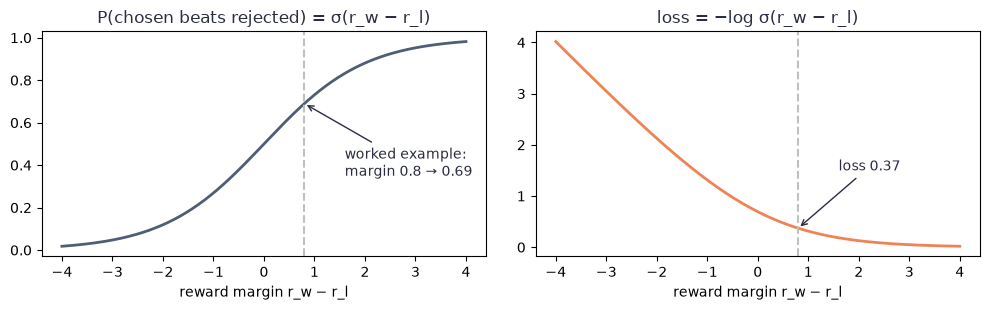

loss 0.371 unchanged after adding 7 to both rewards ✓


In [6]:
delta = torch.linspace(-4, 4, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(delta, torch.sigmoid(delta), color=BLUE, lw=2)
axes[0].set_title("P(chosen beats rejected) = σ(r_w − r_l)", color=INK)
axes[1].plot(delta, -F.logsigmoid(delta), color=ACCENT, lw=2)
axes[1].set_title("loss = −log σ(r_w − r_l)", color=INK)
for ax in axes:
    ax.axvline(0.8, color=SOFT, ls="--"); ax.set_xlabel("reward margin r_w − r_l")
axes[0].annotate("worked example:\nmargin 0.8 → 0.69", (0.8, 0.69), (1.6, 0.35), arrowprops=dict(arrowstyle="->", color=INK), color=INK)
axes[1].annotate("loss 0.37", (0.8, 0.371), (1.6, 1.5), arrowprops=dict(arrowstyle="->", color=INK), color=INK)
plt.tight_layout(); plt.show()

# only differences matter
r_w, r_l = torch.tensor([1.2]), torch.tensor([0.4])
assert torch.isclose(-F.logsigmoid(r_w - r_l), -F.logsigmoid((r_w + 7) - (r_l + 7)))
print("loss", round(-F.logsigmoid(r_w - r_l).item(), 3), "unchanged after adding 7 to both rewards ✓")

**Training the critic.** Real reward models are a full LLM with a scalar head. Ours is a small MLP that sees the order and a bag of response tokens. We collect 4,000 votes from **careful annotators**, who pick the truly better dish with probability $\sigma(q_w - q_l)$, so they sometimes disagree, like real people.

In [7]:
def features(dish, resp):
    x = torch.zeros(len(DISHES) + len(vocab))
    x[DISHES.index(dish)] = 1                               # which dish was ordered
    for w in resp:
        x[len(DISHES) + stoi[w]] += 1                       # token counts of the response
    return x

class RewardModel(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, 32), nn.Tanh(), nn.Linear(32, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

def collect_votes(n_votes, garnish_bias=0.0, seed=0):
    # annotators prefer a with probability σ(q_a − q_b + garnish_bias · (parsley_a − parsley_b))
    g = torch.Generator().manual_seed(seed)
    votes = []
    for _ in range(n_votes):
        d = DISHES[torch.randint(3, (1,), generator=g).item()]
        a, b = [NAMES[i] for i in torch.randperm(len(NAMES), generator=g)[:2].tolist()]
        z = true_quality(a, d) - true_quality(b, d) + garnish_bias * (
            response(a, d).count("parsley") - response(b, d).count("parsley"))
        votes.append((d, a, b) if torch.rand(1, generator=g).item() < torch.sigmoid(torch.tensor(z)).item() else (d, b, a))
    return votes

def train_reward_model(votes, steps=300, seed=0):
    torch.manual_seed(seed)
    rm = RewardModel(len(DISHES) + len(vocab))
    opt = torch.optim.Adam(rm.parameters(), lr=1e-2)
    Xw = torch.stack([features(d, response(w, d)) for d, w, l in votes])
    Xl = torch.stack([features(d, response(l, d)) for d, w, l in votes])
    for _ in range(steps):
        loss = -F.logsigmoid(rm(Xw) - rm(Xl)).mean()          # Bradley–Terry
        opt.zero_grad(); loss.backward(); opt.step()
    acc = (rm(Xw) > rm(Xl)).float().mean().item()
    return rm, loss.item(), acc

@torch.no_grad()
def rewards_of(rm, dish="soup"):
    return rm(torch.stack([features(dish, response(n, dish)) for n in NAMES]))

critic, loss, acc = train_reward_model(collect_votes(4000))
r_clean = rewards_of(critic)
print(f"final loss {loss:.3f} | agrees with the annotators on {acc:.0%} of votes")
for n, r, q in zip(NAMES, r_clean.tolist(), Q_TRUE.tolist()):
    print(f"  {n:8s} reward {r:6.2f}   true quality {q:5.1f}")
assert torch.equal(torch.argsort(r_clean), torch.argsort(Q_TRUE)), "the critic should rank dishes like the hidden rule"
print("the critic ranks all six dishes in the true order ✓")

final loss 0.436 | agrees with the annotators on 80% of votes
  plain    reward   1.17   true quality   1.0
  polite   reward   2.15   true quality   2.0
  curt     reward   0.75   true quality   0.5
  garnish  reward   1.73   true quality   1.5
  heap     reward  -0.09   true quality  -0.5
  wrong    reward  -1.49   true quality  -2.0
the critic ranks all six dishes in the true order ✓


The critic agrees with only part of the votes because the annotators are noisy, yet it recovers the **true ranking** of all six dishes. Its numbers are on a different scale from the true quality; only the order and the differences carry meaning.

**In the kitchen.** The critic never tasted a recipe book; it learned the customers' taste purely from which of two plates they picked.

## 4. RLHF: maximize reward, stay close to the reference

With a reward model in hand, RLHF fine-tunes the policy $\pi_\theta$ (the apprentice) to earn high reward, while a **KL penalty** keeps it close to the SFT reference:

$$
\max_{\pi_\theta}\; \mathbb{E}_{x,\;y\sim\pi_\theta}\big[r_\phi(x,y)\big] \;-\; \beta\, \mathrm{KL}\big(\pi_\theta(\cdot\mid x)\,\Vert\,\pi_{\text{ref}}(\cdot\mid x)\big).
$$

Why the KL term is needed:

| Without it | Because |
|---|---|
| the policy finds answers the reward model overrates | the reward model is only accurate near the data it was trained on (Part 7) |
| fluency and knowledge from pretraining erode | nothing ties the policy to the language it already speaks |
| outputs collapse to one "best" answer | maximizing a single score has no reason to keep variety |

This objective has a **closed-form optimum**, which DPO builds on:

$$
\pi^*(y\mid x) = \frac{1}{Z(x)}\,\pi_{\text{ref}}(y\mid x)\,\exp\!\big(r(x,y)/\beta\big),\qquad Z(x)=\sum_y \pi_{\text{ref}}(y\mid x)\,\exp\!\big(r(x,y)/\beta\big).
$$

Small $\beta$: the coach is weak and $\pi^*$ piles onto the highest-reward answer. Large $\beta$: the coach wins and $\pi^*\approx\pi_{\text{ref}}$. With only six candidate answers we can compute $\pi^*$ exactly; drag $\beta$ below.

**In the kitchen.** The apprentice cooks, the critic scores, and the coach charges a fee for every step away from the head chef's style. $\beta$ is how expensive that fee is.

In [8]:
# Interactive: drag β. The exact RLHF optimum π* ∝ π_ref · exp(r/β) over the six answers, using the clean critic.
def rlhf_optimum(rewards, beta, prior=pi_ref):
    w = prior * torch.exp((rewards - rewards.max()) / beta)
    return w / w.sum()

def kl(p, q):
    return (p * (p.clamp_min(1e-12) / q).log()).sum().item()

betas = [8, 4, 2, 1.5, 1, 0.7, 0.5, 0.35, 0.25, 0.15, 0.1, 0.05]
default = betas.index(0.5)
fig = go.Figure()
titles = []
for b in betas:
    pi = rlhf_optimum(r_clean, b)
    fig.add_bar(x=NAMES, y=pi_ref.tolist(), name="π_ref (SFT apprentice)", marker_color=SOFT, visible=(b == betas[default]))
    fig.add_bar(x=NAMES, y=pi.tolist(), name="π* (after RLHF)", marker_color=ACCENT, visible=(b == betas[default]))
    titles.append(f"β = {b}: KL(π*‖π_ref) = {kl(pi, pi_ref):.2f}, expected true quality "
                  f"{(pi_ref * Q_TRUE).sum():.2f} → {(pi * Q_TRUE).sum():.2f}")
steps = [dict(method="update", label=str(b), args=[{"visible": [j // 2 == i for j in range(2 * len(betas))]},
                                                   {"title.text": titles[i]}]) for i, b in enumerate(betas)]
fig.update_layout(barmode="group", height=420, title=titles[default], yaxis=dict(range=[0, 1], title="probability"),
                  sliders=[dict(active=default, steps=steps, pad={"t": 40}, currentvalue={"prefix": "β = "})])
fig.show()

At $\beta = 0.5$ (the default) the polite answer has become the most likely one and the wrong-dish answer has almost vanished, while the plain answer keeps a large share: the coach still holds the apprentice near the head chef's habits. At $\beta = 1$ the optimum mostly just removes the bad answers; near $\beta = 0.25$ the polite answer takes over 80%; push $\beta$ further down and it becomes almost one-hot.

### How RLHF actually optimizes it: PPO in four models

Real RLHF cannot enumerate all answers, so it samples responses and uses PPO (Schulman et al., 2017). Four models are in memory at once:

| Model | Role | Trained? |
|---|---|---|
| policy $\pi_\theta$ | generates responses (the apprentice) | yes |
| reference $\pi_{\text{ref}}$ | the frozen SFT model, for the KL penalty (the coach's memory of the head chef) | no |
| reward model $r_\phi$ | scores each finished response (the critic) | no |
| value model $V_\psi$ | predicts the expected reward from a partial response, to turn one final score into per-token credit | yes |

For a 7B model that is four 7B-sized networks, two of them with optimizer states. That cost is the main reason DPO and, later, GRPO (notebook `10`) became popular.

PPO's update is a **clipped** policy-gradient step. With probability ratio $\rho = \pi_\theta(y_t\mid\cdot)/\pi_{\text{old}}(y_t\mid\cdot)$ and advantage $A$ (how much better than expected),

$$
L^{\text{CLIP}} = \min\big(\rho A,\ \operatorname{clip}(\rho, 1-\epsilon, 1+\epsilon)\,A\big).
$$

Once a token's probability has moved by more than $\epsilon$ (typically 0.2) in the helpful direction, the objective goes flat and stops pushing. GRPO reuses this clipping.

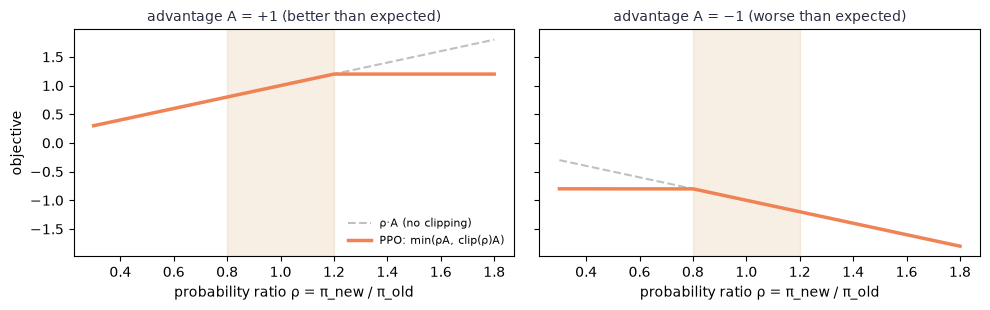

In [9]:
rho = torch.linspace(0.3, 1.8, 300)
eps = 0.2
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, A, title in [(axes[0], 1.0, "advantage A = +1 (better than expected)"), (axes[1], -1.0, "advantage A = −1 (worse than expected)")]:
    unclipped, clipped = rho * A, torch.clamp(rho, 1 - eps, 1 + eps) * A
    ax.plot(rho, unclipped, color=SOFT, ls="--", label="ρ·A (no clipping)")
    ax.plot(rho, torch.minimum(unclipped, clipped), color=ACCENT, lw=2.5, label="PPO: min(ρA, clip(ρ)A)")
    ax.axvspan(1 - eps, 1 + eps, color=GOLD, alpha=0.2)
    ax.set_title(title, color=INK, fontsize=10); ax.set_xlabel("probability ratio ρ = π_new / π_old")
axes[0].set_ylabel("objective"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

Left: once $\rho > 1.2$ the objective is flat, so there is no gradient to push a good token further in one update. Right: once $\rho < 0.8$ the same happens for a bad token. Each update can only take a small, trusted step.

<details><summary><b>Quick check:</b> why does PPO need a value model, while our six-answer example did not?</summary>

The reward arrives only at the end of a response. To decide which *tokens* deserve credit, PPO compares the final reward with the value model's prediction at each step (the advantage). In the toy example we scored whole answers directly and solved for $\pi^*$ exactly, so no per-token credit assignment was needed.
</details>

## 5. DPO: the same goal without a reward model

DPO (Rafailov et al., 2023) starts from the closed-form optimum of Part 4 and solves it for the reward:

$$
r(x,y) = \beta \log\frac{\pi^*(y\mid x)}{\pi_{\text{ref}}(y\mid x)} + \beta\log Z(x).
$$

Plug this into the Bradley–Terry model. The awkward $\beta\log Z(x)$ term is the same for $y_w$ and $y_l$, so it **cancels in the difference**:

$$
P(y_w\succ y_l\mid x)=\sigma\!\Big(\beta\log\frac{\pi_\theta(y_w\mid x)}{\pi_{\text{ref}}(y_w\mid x)}-\beta\log\frac{\pi_\theta(y_l\mid x)}{\pi_{\text{ref}}(y_l\mid x)}\Big),
$$

and maximizing the likelihood of the votes gives the **DPO loss**

$$
\mathcal{L}_{\text{DPO}} = -\log\sigma\Big(\beta\big[\underbrace{(\log\pi_\theta(y_w)-\log\pi_{\text{ref}}(y_w))}_{\text{implicit reward of } y_w\,/\,\beta}-\underbrace{(\log\pi_\theta(y_l)-\log\pi_{\text{ref}}(y_l))}_{\text{implicit reward of } y_l\,/\,\beta}\big]\Big).
$$

The policy *is* the reward model: $\hat r(x,y)=\beta\log\pi_\theta(y\mid x)/\pi_{\text{ref}}(y\mid x)$. No critic, no sampling, no value model; only the policy and a frozen reference, trained on a fixed set of votes like ordinary supervised learning.

**In the kitchen.** Instead of hiring a critic and cooking for it, the apprentice reads the vote cards directly: "make the chosen dish a bit more like me, the rejected one a bit less, compared with how the head chef would have done it."

📗 *[DPO bonus] code.* Raschka's loss function and log-probability helper:

In [10]:
# Source: Raschka, LLMs-from-scratch, ch07/04_preference-tuning-with-dpo/dpo-from-scratch.ipynb
def compute_dpo_loss(
      model_chosen_logprobs,
      model_rejected_logprobs,
      reference_chosen_logprobs,
      reference_rejected_logprobs,
      beta=0.1,
    ):
    model_logratios = model_chosen_logprobs - model_rejected_logprobs
    reference_logratios = reference_chosen_logprobs - reference_rejected_logprobs
    logits = model_logratios - reference_logratios

    # DPO (Eq. 7 of https://arxiv.org/pdf/2305.18290.pdf)
    losses = -F.logsigmoid(beta * logits)

    # Optional values to track progress during training
    chosen_rewards = (model_chosen_logprobs - reference_chosen_logprobs).detach()
    rejected_rewards = (model_rejected_logprobs - reference_rejected_logprobs).detach()

    # .mean() to average over the samples in the batch
    return losses.mean(), chosen_rewards.mean(), rejected_rewards.mean()


def compute_logprobs(logits, labels, selection_mask=None):
    # Labels are the inputs shifted by one
    labels = labels[:, 1:].clone()

    # Truncate logits to match the labels num_tokens
    logits = logits[:, :-1, :]

    log_probs = F.log_softmax(logits, dim=-1)

    # Gather the log probabilities for the actual labels
    selected_log_probs = torch.gather(
        input=log_probs,
        dim=-1,
        index=labels.unsqueeze(-1)
    ).squeeze(-1)

    if selection_mask is not None:
        mask = selection_mask[:, 1:].clone()

        # Apply the mask to filter out padding tokens
        selected_log_probs = selected_log_probs * mask

        # Calculate the average log probability excluding padding tokens
        # This averages over the tokens, so the shape is (batch_size,)
        avg_log_prob = selected_log_probs.sum(-1) / mask.sum(-1)

        return avg_log_prob

    else:
        return selected_log_probs.mean(-1)

- `selection_mask` keeps only the response tokens, so the prompt and padding do not count.
- Raschka's helper **averages** the log-probabilities over the response tokens, while the DPO paper uses their **sum**. Averaging makes long and short answers comparable (a length normalization); the sum is the exact sequence log-probability. Both appear in practice.

📗 *[DPO bonus] code, adapted.* The batch function and a minimal training loop, as in Raschka's notebook but on our vote cards:

In [11]:
# Source: adapted from Raschka, dpo-from-scratch.ipynb (compute_dpo_loss_batch, train_model_dpo_simple)
def compute_dpo_loss_batch(batch, policy_model, reference_model, beta):
    policy_chosen = compute_logprobs(policy_model(batch["chosen"]), batch["chosen"], batch["chosen_mask"])
    policy_rejected = compute_logprobs(policy_model(batch["rejected"]), batch["rejected"], batch["rejected_mask"])
    with torch.no_grad():
        ref_chosen = compute_logprobs(reference_model(batch["chosen"]), batch["chosen"], batch["chosen_mask"])
        ref_rejected = compute_logprobs(reference_model(batch["rejected"]), batch["rejected"], batch["rejected_mask"])
    return compute_dpo_loss(policy_chosen, policy_rejected, ref_chosen, ref_rejected, beta=beta)

chosen_ids, chosen_mask = batchify([encode(d, response(w, d)) for d, w, l in pairs])
rejected_ids, rejected_mask = batchify([encode(d, response(l, d)) for d, w, l in pairs])
batch = {"chosen": chosen_ids, "chosen_mask": chosen_mask, "rejected": rejected_ids, "rejected_mask": rejected_mask}

def train_dpo(beta=0.1, steps=60, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    policy = copy.deepcopy(ref)
    for p in policy.parameters():
        p.requires_grad_(True)
    opt = torch.optim.Adam(policy.parameters(), lr=lr)       # only the policy is optimized
    log = []
    for step in range(steps):
        loss, chosen_r, rejected_r = compute_dpo_loss_batch(batch, policy, ref, beta)
        opt.zero_grad(); loss.backward(); opt.step()
        log.append((loss.item(), chosen_r.item(), rejected_r.item()))
    return policy, np.array(log)

policy, log = train_dpo()
p_dpo = candidate_probs(policy)
pi_dpo = p_dpo / p_dpo.sum()
print(f"DPO loss {log[0, 0]:.3f} -> {log[-1, 0]:.3f}")
print(f"expected true quality: SFT {(pi_ref * Q_TRUE).sum():.2f} -> DPO {(pi_dpo * Q_TRUE).sum():.2f}")

DPO loss 0.693 -> 0.625
expected true quality: SFT 0.21 -> DPO 1.81


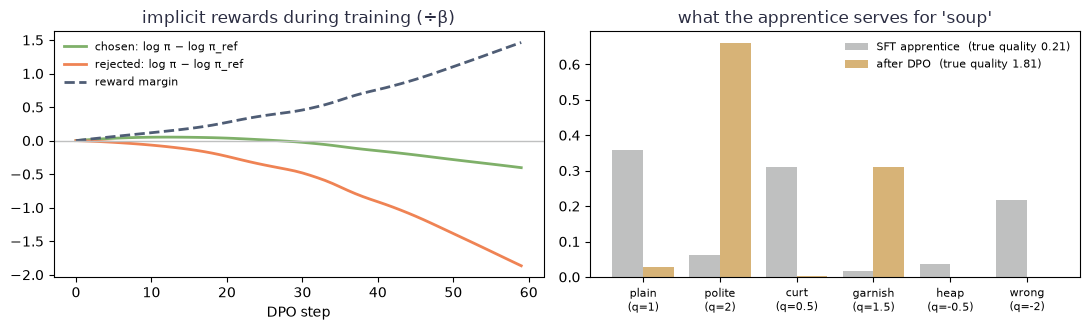

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(log[:, 1], color=GREEN, lw=2, label="chosen: log π − log π_ref")
axes[0].plot(log[:, 2], color=ACCENT, lw=2, label="rejected: log π − log π_ref")
axes[0].plot(log[:, 1] - log[:, 2], color=BLUE, lw=2, ls="--", label="reward margin")
axes[0].axhline(0, color=SOFT, lw=1)
axes[0].set_xlabel("DPO step"); axes[0].set_title("implicit rewards during training (÷β)", color=INK)
axes[0].legend(frameon=False, fontsize=8)

x = np.arange(len(NAMES))
axes[1].bar(x - 0.2, pi_ref, 0.4, color=SOFT, label=f"SFT apprentice  (true quality {(pi_ref * Q_TRUE).sum():.2f})")
axes[1].bar(x + 0.2, pi_dpo, 0.4, color=GOLD, label=f"after DPO  (true quality {(pi_dpo * Q_TRUE).sum():.2f})")
axes[1].set_xticks(x, [f"{n}\n(q={q:g})" for n, q in zip(NAMES, Q_TRUE.tolist())], fontsize=8)
axes[1].set_title("what the apprentice serves for 'soup'", color=INK); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

Two things to notice:

- The apprentice now serves the polite answer most of the time, and curt or wrong answers almost never: expected true quality rises sharply after 60 small steps on 45 vote cards.
- **The chosen implicit reward goes negative too.** DPO only cares about the *margin*; it can lower the probability of chosen answers as long as rejected answers fall faster. This is a known weakness ("likelihood displacement") and an interview favourite.

<details><summary><b>Quick check:</b> what is the DPO loss at step 0, before any update, and why?</summary>

$\ln 2 \approx 0.693$. The policy starts as a copy of the reference, so both log-ratios are 0, the argument of $\sigma$ is 0, and $-\log\sigma(0)=\ln 2$.
</details>

## 6. Tests, β, and training too long

Three properties any DPO implementation should pass, checked instead of eyeballed:

In [13]:
# 1. policy == reference  ->  loss is exactly ln 2 and both implicit rewards are 0
loss0, c0, r0 = compute_dpo_loss_batch(batch, copy.deepcopy(ref), ref, beta=0.1)
assert math.isclose(loss0.item(), math.log(2), rel_tol=1e-6) and c0 == 0 and r0 == 0
print(f"policy = reference: loss = {loss0.item():.4f} = ln 2 ✓")

# 2. one gradient step increases the reward margin
pol = copy.deepcopy(ref).requires_grad_(True)
opt = torch.optim.SGD(pol.parameters(), lr=0.5)
loss, c, r = compute_dpo_loss_batch(batch, pol, ref, beta=0.1)
opt.zero_grad(); loss.backward(); opt.step()
_, c1, r1 = compute_dpo_loss_batch(batch, pol, ref, beta=0.1)
assert (c1 - r1) > (c - r)
print(f"one step: margin {(c - r).item():.4f} -> {(c1 - r1).item():.4f} ✓")

# 3. the partition function cancels: shifting both log-probs of a pair by the same constant changes nothing
lw, ll, rw, rl = torch.randn(4, 8)
assert torch.allclose(compute_dpo_loss(lw + 3.0, ll + 3.0, rw, rl)[0], compute_dpo_loss(lw, ll, rw, rl)[0])
print("adding the same constant to log π(y_w) and log π(y_l) leaves the loss unchanged ✓")

policy = reference: loss = 0.6931 = ln 2 ✓
one step: margin -0.0000 -> 0.0092 ✓
adding the same constant to log π(y_w) and log π(y_l) leaves the loss unchanged ✓


**What β does.** $\beta$ scales how strongly the log-ratios are pushed. Same data, same 60 steps:

In [14]:
print(f"{'β':>5s} {'final loss':>11s} {'KL(π‖π_ref)':>12s} {'true quality':>13s} {'mass on 6 answers':>18s}")
for b in [0.05, 0.1, 0.5, 1.0]:
    pol, lg = train_dpo(beta=b)
    p = candidate_probs(pol); pn = p / p.sum()
    print(f"{b:5.2f} {lg[-1, 0]:11.3f} {kl(pn, pi_ref):12.2f} {(pn * Q_TRUE).sum():13.2f} {p.sum():18.2f}")

    β  final loss  KL(π‖π_ref)  true quality  mass on 6 answers


 0.05       0.658         2.41          1.82               0.89


 0.10       0.625         2.41          1.81               0.89


 0.50       0.438         2.40          1.76               0.84


 1.00       0.313         2.25          1.74               0.79


Read this table carefully. $\beta$ multiplies the log-ratio gap inside the loss, so **final losses are not comparable across $\beta$** (a larger $\beta$ gives a lower number for the same policy). In a short run the policy moves about the same distance for every $\beta$. Where $\beta$ matters is the destination: the DPO loss is minimized by the RLHF optimum $\pi^*\propto\pi_{\text{ref}}e^{r/\beta}$, which stays closer to the reference for larger $\beta$ (the slider in Part 4). Raschka uses $\beta=0.1$ for GPT-2 medium and suggests up to 0.5 for a weaker effect.

**Training too long.** Raschka trains for a single epoch with a tiny learning rate because "DPO is very prone to collapse". In the toy kitchen we can watch it happen: keep training, and track how much probability the apprentice still puts on the six real answers.

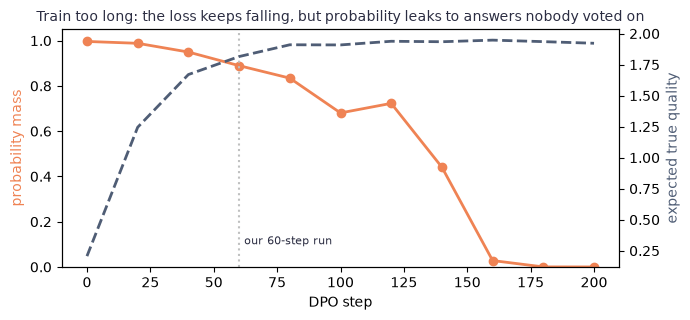

In [15]:
masses, qualities, ckpt = [], [], list(range(0, 201, 20))
torch.manual_seed(0)
pol = copy.deepcopy(ref).requires_grad_(True); opt = torch.optim.Adam(pol.parameters(), lr=1e-3)
for step in range(201):
    if step in ckpt:
        p = candidate_probs(pol); masses.append(p.sum().item()); qualities.append(((p / p.sum()) * Q_TRUE).sum().item())
    loss, _, _ = compute_dpo_loss_batch(batch, pol, ref, 0.1)
    opt.zero_grad(); loss.backward(); opt.step()

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(ckpt, masses, color=ACCENT, lw=2, marker="o", label="probability on the six real answers")
ax.set_xlabel("DPO step"); ax.set_ylabel("probability mass", color=ACCENT); ax.set_ylim(0, 1.05)
ax2 = ax.twinx(); ax2.plot(ckpt, qualities, color=BLUE, lw=2, ls="--", label="true quality (among the six)")
ax2.set_ylabel("expected true quality", color=BLUE)
ax.axvline(60, color=SOFT, ls=":"); ax.text(62, 0.1, "our 60-step run", color=INK, fontsize=8)
ax.set_title("Train too long: the loss keeps falling, but probability leaks to answers nobody voted on", color=INK, fontsize=10)
plt.tight_layout(); plt.show()

Among the six answers, quality looks great. But the policy puts less and less probability on *any* of them: DPO only pushes chosen above rejected, and nothing stops probability from flowing to strings that never appear in the votes (for a real model, degenerate text). The loss curve alone hides this, which is why Raschka checks sample outputs and why practitioners train DPO briefly, with small learning rates, and evaluate generations.

**In the kitchen.** Read the vote cards too many times and the apprentice starts inventing dishes that were never on any card.

## 7. Reward hacking: when the critic loves garnish

A reward model is a learned **proxy** for what people want. Suppose the annotators had a bias: plates with parsley look nicer, so they lean toward garnish, $P(a\succ b)=\sigma(q_a-q_b+\lambda\,(\text{parsley}_a-\text{parsley}_b))$. The critic faithfully learns that bias. Now optimize against it with the RLHF optimum of Part 4 and lower $\beta$ step by step, letting the policy move further from the reference (larger KL):

critic rewards    {'plain': 2.12, 'polite': 3.05, 'curt': 1.68, 'garnish': 3.77, 'heap': 4.4, 'wrong': -0.73}


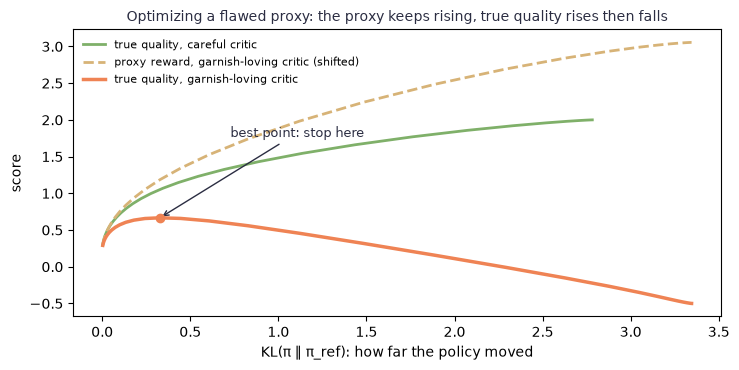

garnish-loving critic: true quality 0.29 -> peak 0.67 -> -0.50 at KL 3.35


In [16]:
biased_critic, _, _ = train_reward_model(collect_votes(4000, garnish_bias=1.2))
r_biased = rewards_of(biased_critic)
print("critic rewards   ", {n: round(v, 2) for n, v in zip(NAMES, r_biased.tolist())})

beta_grid = torch.logspace(1.2, -1.5, 40)
def overopt_curve(rewards):
    rows = []
    for b in beta_grid:
        pi = rlhf_optimum(rewards, b.item())
        rows.append((kl(pi, pi_ref), (pi * rewards).sum().item(), (pi * Q_TRUE).sum().item()))
    return np.array(rows)

clean, biased = overopt_curve(r_clean), overopt_curve(r_biased)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(clean[:, 0], clean[:, 2], color=GREEN, lw=2, label="true quality, careful critic")
ax.plot(biased[:, 0], biased[:, 1] - biased[0, 1] + biased[0, 2], color=GOLD, lw=2, ls="--",
        label="proxy reward, garnish-loving critic (shifted)")
ax.plot(biased[:, 0], biased[:, 2], color=ACCENT, lw=2.5, label="true quality, garnish-loving critic")
peak = biased[:, 2].argmax()
ax.scatter([biased[peak, 0]], [biased[peak, 2]], color=ACCENT, zorder=5)
ax.annotate("best point: stop here", (biased[peak, 0], biased[peak, 2]), (biased[peak, 0] + 0.4, biased[peak, 2] + 1.1),
            arrowprops=dict(arrowstyle="->", color=INK), color=INK, fontsize=9)
ax.set_xlabel("KL(π ‖ π_ref): how far the policy moved"); ax.set_ylabel("score")
ax.set_title("Optimizing a flawed proxy: the proxy keeps rising, true quality rises then falls", color=INK, fontsize=10)
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()
print(f"garnish-loving critic: true quality {biased[0, 2]:.2f} -> peak {biased[peak, 2]:.2f} -> {biased[-1, 2]:.2f} at KL {biased[-1, 0]:.2f}")

With the careful critic (green), moving away from the reference only helps. With the garnish-loving critic, the proxy reward (dashed) climbs the whole way, while true quality first improves (the policy stops answering curtly or with the wrong dish) and then **collapses** as it learns to pile on parsley. This rise-then-fall shape is what Gao et al. (2022) measured for real reward models as the policy moves further from its starting point.

The interactive version: change how much the annotators love garnish.

In [17]:
# Interactive: drag the annotators' garnish bias λ; each step trains a new critic on new votes (precomputed here).
lambdas = [0.0, 0.4, 0.8, 1.0, 1.2, 1.6, 2.0]
default = lambdas.index(1.2)
fig = go.Figure(); titles = []
for lam in lambdas:
    rm_l, _, _ = train_reward_model(collect_votes(4000, garnish_bias=lam))
    cur = overopt_curve(rewards_of(rm_l))
    vis = lam == lambdas[default]
    fig.add_scatter(x=cur[:, 0], y=cur[:, 2], mode="lines", line=dict(color=ACCENT, width=3), name="true quality", visible=vis)
    fig.add_scatter(x=cur[:, 0], y=cur[:, 1] - cur[0, 1] + cur[0, 2], mode="lines", line=dict(color=GOLD, dash="dash"),
                    name="proxy reward (shifted)", visible=vis)
    titles.append(f"garnish bias λ = {lam}: true quality peaks at {cur[:, 2].max():.2f}, ends at {cur[-1, 2]:.2f}")
steps = [dict(method="update", label=str(l), args=[{"visible": [j // 2 == i for j in range(2 * len(lambdas))]},
                                                   {"title.text": titles[i]}]) for i, l in enumerate(lambdas)]
fig.update_layout(height=420, title=titles[default], xaxis_title="KL(π ‖ π_ref)", yaxis=dict(range=[-1, 4.5], title="score"),
                  sliders=[dict(active=default, steps=steps, pad={"t": 40}, currentvalue={"prefix": "λ = "})])
fig.show()

| Mitigation | Why it helps |
|---|---|
| KL penalty / early stopping | keeps the policy where the reward model is still accurate (the left part of the curve) |
| better reward data: more, diverse, debiased annotators | removes the bias at its source |
| reward-model ensembles; penalize disagreement | a hack that fools one critic rarely fools all |
| length or format normalization | targets the most common real bias: longer answers look better |
| refresh the reward model on the new policy's outputs | the critic learns about the dishes the apprentice now actually cooks |
| keep human or held-out evaluation | the only check on the *true* quality, which the proxy cannot see |

**In the kitchen.** The critic loved garnish a little; the apprentice learned to love it a lot. Notebook `10` returns to this with verifiers that can be fooled.

## 8. The real run: Raschka's DPO on GPT-2 medium

📗 *[DPO bonus] training log and outputs*

Raschka applies exactly the loss above to GPT-2 medium (355M parameters) after instruction fine-tuning, on the 1,100 politeness pairs, with $\beta = 0.1$, AdamW at learning rate $5\times10^{-6}$, for one epoch. We do not rerun it; his notebook saved the training log and before/after answers, which we load from `08-preference_tuning_rlhf_dpo/data/`.

24 logged evaluations, steps 0 to 115


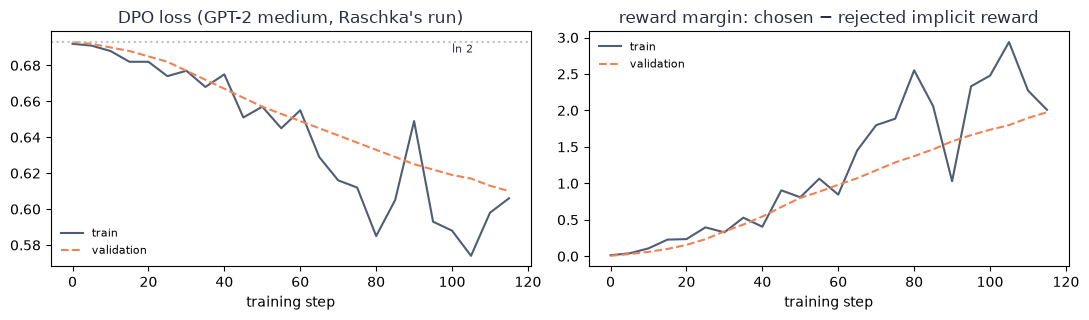

In [18]:
def fetch(name):
    # local copy -> this repo on GitHub
    local = os.path.join("08-preference_tuning_rlhf_dpo", "data", name)
    if os.path.exists(local):
        return open(local, encoding="utf-8").read()
    url = f"https://raw.githubusercontent.com/chungenyu6/ai-learning-notebooks/main/02-LLM/live/08-preference_tuning_rlhf_dpo/data/{name}"
    return urllib.request.urlopen(url).read().decode("utf-8")

import re
rows = [re.findall(r"[-\d.]+", line) for line in fetch("dpo_gpt2_medium_log.txt").splitlines() if line.startswith("Ep ")]
real = np.array([[float(v) for v in r[1:6]] for r in rows])   # step, train loss, val loss, train margin, val margin
print(len(real), "logged evaluations, steps", int(real[0, 0]), "to", int(real[-1, 0]))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].plot(real[:, 0], real[:, 1], color=BLUE, label="train"); axes[0].plot(real[:, 0], real[:, 2], color=ACCENT, ls="--", label="validation")
axes[0].axhline(math.log(2), color=SOFT, ls=":"); axes[0].text(100, math.log(2) - 0.006, "ln 2", color=INK, fontsize=8)
axes[0].set_title("DPO loss (GPT-2 medium, Raschka's run)", color=INK)
axes[1].plot(real[:, 0], real[:, 3], color=BLUE, label="train"); axes[1].plot(real[:, 0], real[:, 4], color=ACCENT, ls="--", label="validation")
axes[1].set_title("reward margin: chosen − rejected implicit reward", color=INK)
for ax in axes:
    ax.set_xlabel("training step"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

The same signatures as in the toy kitchen: the loss starts at $\ln 2$ and falls slowly (one epoch, small learning rate), and the reward margin grows steadily on both training and validation pairs, so the policy is not just memorizing the training votes. Did the *style* change? His saved answers, reference model vs DPO policy:

In [19]:
samples = json.loads(fetch("dpo_gpt2_medium_samples.json"))
for s in samples:
    task = s["instruction"] + (f"  [{s['input']}]" if s["input"] else "")
    print(f"{s['split']:10s} | {task}\n{'':10s} | before DPO: {s['reference']}\n{'':10s} | after DPO:  {s['policy']}\n")

validation | Convert the active sentence to passive: 'The chef cooks the meal every day.'
           | before DPO: The meal is cooked everyday by the chef.
           | after DPO:  The meal was prepared by the chef.

validation | Classify an input string as either a noun or a verb.  [Dance]
           | before DPO: Dance is a verb.
           | after DPO:  The input 'Dance' could be classified as a verb.

validation | Rewrite the sentence using a metaphor.  [The book is very interesting.]
           | before DPO: The book is a book.
           | after DPO:  The book would be of great interest.

test       | Rewrite the sentence using a simile.  [The car is very fast.]
           | before DPO: The car is as fast as a bullet.
           | after DPO:  The car would be very fast.

test       | What type of cloud is typically associated with thunderstorms?
           | before DPO: The type of cloud associated with thunderstorms is a cumulus cloud.
           | after DPO:  The type of cloud 

Several answers shift toward the tentative, gentler phrasing the votes preferred ("could be classified", "would be"), and one is unchanged. Some get *worse* ("The book would be of great interest" no longer uses a metaphor; "The car would be very fast" drops the simile): the votes rewarded tone, not task accuracy, and DPO optimizes exactly what the votes reward. Small-model DPO is a style nudge, not a capability upgrade.

## 9. Check yourself (interview-style)

<details><summary><b>Q1. Walk through SFT → reward model → RLHF → DPO. What does each stage add?</b></summary>

SFT copies demonstrations, so the model follows instructions but cannot tell two acceptable answers apart. A reward model learns a scalar score from pairwise human votes (Bradley–Terry). RLHF then optimizes the policy to maximize that reward minus $\beta$ times the KL to the SFT model, usually with PPO (policy, reference, reward and value model in memory). DPO reaches the same KL-regularized objective in closed form and trains the policy directly on the votes with a classification-style loss, needing only the policy and a frozen reference.
</details>

<details><summary><b>Q2. Write the reward-model loss. Why do only reward differences matter?</b></summary>

$\mathcal{L}=-\log\sigma(r(x,y_w)-r(x,y_l))$. The Bradley–Terry probability depends on $r_w-r_l$ only, so adding a constant (per prompt) to all rewards changes nothing. Rewards are therefore not calibrated across prompts, which is why RLHF implementations often normalize them.
</details>

<details><summary><b>Q3. Write the DPO loss. What is the "implicit reward"?</b></summary>

$\mathcal{L}_{\text{DPO}}=-\log\sigma\big(\beta[\log\frac{\pi_\theta(y_w)}{\pi_{\text{ref}}(y_w)}-\log\frac{\pi_\theta(y_l)}{\pi_{\text{ref}}(y_l)}]\big)$. It comes from solving the RLHF optimum $\pi^*\propto\pi_{\text{ref}}e^{r/\beta}$ for $r$ and substituting into Bradley–Terry, where the partition function cancels. The implicit reward is $\hat r(x,y)=\beta\log\pi_\theta(y\mid x)/\pi_{\text{ref}}(y\mid x)$: the policy itself acts as the reward model.
</details>

<details><summary><b>Q4. Why does RLHF need the KL penalty? What happens as $\beta\to0$ and $\beta\to\infty$?</b></summary>

The reward model is only reliable near its training distribution, and the policy must keep the fluency of the SFT model. As $\beta\to0$ the policy collapses onto whatever the reward model scores highest, including its errors (reward hacking). As $\beta\to\infty$ the policy cannot move and stays the SFT model.
</details>

<details><summary><b>Q5. PPO keeps four models in memory, DPO two. Which ones, and what does that mean in practice?</b></summary>

PPO: trained policy and value model (with gradients and optimizer states), frozen reference and reward model, plus online generation in the loop. DPO: trained policy and frozen reference; the reference log-probs can even be precomputed once. DPO is far cheaper and simpler, but it is **offline**: it only learns from responses in the fixed dataset, not from the policy's own new outputs.
</details>

<details><summary><b>Q6. What is reward hacking? Two examples and two mitigations.</b></summary>

The policy exploits flaws in a learned proxy reward: true quality falls while the proxy rises. Examples: answers grow longer because annotators and reward models favour length; excessive flattery or hedging; formatting tricks. Mitigations: KL penalty and early stopping, reward-model ensembles, length normalization, refreshing the reward model on new policy outputs, and held-out human evaluation.
</details>

<details><summary><b>Q7. Name weaknesses of DPO.</b></summary>

It is offline (no exploration beyond the dataset); it optimizes the margin, so the likelihood of *chosen* answers can also fall and probability can leak to unseen outputs if trained too long; it is sensitive to $\beta$, learning rate and data quality; and summed log-probabilities make it sensitive to response length (hence length-normalized variants).
</details>

<details><summary><b>Q8. Explain RLHF to a non-engineer in 30 seconds.</b></summary>

"An apprentice chef has read every cookbook and copied the head chef. To learn what customers actually like, the restaurant shows customers two dishes at a time and collects their votes. A critic learns the customers' taste from those votes, and the apprentice practises cooking to please the critic, while a coach stops them from straying too far from what they learned. A shortcut called DPO skips the critic and learns straight from the vote cards." Then map it once: votes = preference data, critic = reward model, coach = KL penalty, apprentice = the policy model.
</details>

## References

- Raschka (2024), *Build a Large Language Model (From Scratch)*; [DPO from scratch](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch07/04_preference-tuning-with-dpo) bonus notebook.
- Ouyang et al. (2022), *Training language models to follow instructions with human feedback* (InstructGPT), [arXiv:2203.02155](https://arxiv.org/abs/2203.02155).
- Schulman et al. (2017), *Proximal Policy Optimization Algorithms*, [arXiv:1707.06347](https://arxiv.org/abs/1707.06347).
- Rafailov et al. (2023), *Direct Preference Optimization: Your Language Model is Secretly a Reward Model*, [arXiv:2305.18290](https://arxiv.org/abs/2305.18290).
- Gao, Schulman & Hilton (2022), *Scaling Laws for Reward Model Overoptimization*, [arXiv:2210.10760](https://arxiv.org/abs/2210.10760).
- Nathan Lambert, *The RLHF Book*, [rlhfbook.com](https://rlhfbook.com/) (chapters on reward models, policy gradients, DPO and over-optimization).